In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import json
import time
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader, Subset, ConcatDataset
from torchvision import datasets, transforms
from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score
from transformers import AutoTokenizer, DistilBertForSequenceClassification

# Problem 1: Window Type Classification (CNN)

In [7]:
# A simple CNN model
class SimpleCNN(nn.Module):
  def __init__(self, num_classes):
    super(SimpleCNN, self).__init__()
    self.conv1 = nn.Conv2d(3, 32, kernel_size=3, stride=1, padding=1)
    self.conv2 = nn.Conv2d(32, 64, kernel_size=3, stride=1, padding=1)
    self.conv3 = nn.Conv2d(64, 128, kernel_size=3, stride=1, padding=1)
    # BEGIN YOUR CODE HERE (~1 line)
    # Task 1 asks you to compute this input dimension BY HAND (channels
    # x height x width of conv3's pooled output, flattened) -- it is
    # deliberately not given to you here. Must match whatever you use in
    # the x.view(...) call in forward() below.
    self.fc1 = nn.Linear(2048, 512)
    # END YOUR CODE HERE
    self.fc2 = nn.Linear(512, num_classes)
    self.pool = nn.MaxPool2d(2, 2)

  def forward(self, x):
    x = self.pool(torch.relu(self.conv1(x)))
    x = self.pool(torch.relu(self.conv2(x)))
    x = self.pool(torch.relu(self.conv3(x)))
    # BEGIN YOUR CODE HERE (~1 line)
    # Same flattened size as fc1's input dimension above.
    x = x.view(-1, 2048)
    # END YOUR CODE HERE
    x = torch.relu(self.fc1(x))
    x = self.fc2(x)
    # x = torch.softmax(x, dim=1) <--- the bug for Task 2
    return x

## Task 1: Compute fc1's input dimension by hand

`SimpleCNN` above deliberately leaves `fc1`'s input dimension (and the matching `x.view(-1, ...)` call) blank. Compute it yourself: starting from the $32\times32\times3$ input, work out the output shape (channels $\times$ height $\times$ width) after `conv1`, its pooling layer, `conv2`, its pooling layer, `conv3`, and its pooling layer. Fill in the table below, then use the flattened size to fill in the two blanks in `SimpleCNN` above.

### Task 1 answer

_Fill in the shape after each layer, then compute the final flattened size. Double-click this cell to edit._

| layer | channels | height | width |
|---|---|---|---|
| input | 3 | 32 | 32 |
| conv1 | 32 | 32 | 32 |
| pool | 32 | 16 | 16 |
| conv2 | 64 | 16 | 16 |
| pool | 64 | 8 | 8 |
| conv3 | 128 | 8 | 8 |
| pool | 128 | 4 | 4 |

_Flattened size (channels $\times$ height $\times$ width) = (128 $\times$ 4 $\times$ 4) = 2048_

In [8]:
# Sanity check: fc1's shape doesn't depend on num_classes, so instantiate
# SimpleCNN with any placeholder value here and print its architecture --
# confirm the printed Linear(in_features=..., out_features=512) matches
# the flattened size you computed above.
print(SimpleCNN(num_classes=1))

SimpleCNN(
  (conv1): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv3): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (fc1): Linear(in_features=2048, out_features=512, bias=True)
  (fc2): Linear(in_features=512, out_features=1, bias=True)
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
)


In [9]:
# augmentation method can be added in training
# keep validation clean
train_transform = transforms.Compose([
    transforms.Resize((32, 32)),
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
])

val_transform = transforms.Compose([
    transforms.Resize((32, 32)),
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
])

dataset_dir = "data/train_set"

full_train_dataset = datasets.ImageFolder(root=dataset_dir, transform=train_transform)
full_val_dataset = datasets.ImageFolder(root=dataset_dir, transform=val_transform)  # same images, clean (no-augmentation) transform

# BEGIN YOUR CODE HERE (~4-8 lines)
# windows_test_set.zip ships unlabeled (see Problem 1's "About the test
# set" note) -- this train/val split is the ONLY way to get an accuracy
# number before final grading. Split the indices of full_train_dataset
# into disjoint train_idx/val_idx, stratified by class (each class
# should be represented proportionally in both splits). Hint: use
# full_train_dataset.targets, e.g. with
# sklearn.model_selection.train_test_split(..., stratify=...). A common
# split is 80% train / 20% val.
indices = list(range(len(full_train_dataset)))
train_idx, val_idx = train_test_split(indices, test_size=0.2, stratify=full_train_dataset.targets, random_state=42)
# END YOUR CODE HERE

train_dataset = Subset(full_train_dataset, train_idx)
val_dataset = Subset(full_val_dataset, val_idx)

train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=1000, shuffle=False)


## Figure out the number of classes

Don't hardcode the number of classes anywhere below -- read it off of `train_dataset` itself.

In [10]:
# BEGIN YOUR CODE HERE (~1-2 lines)
# Figure out the number of classes directly from full_train_dataset (an
# ImageFolder) -- don't hardcode it. Hint: check what attributes an
# ImageFolder dataset exposes for its classes.
num_classes = len(full_train_dataset.classes)
# END YOUR CODE HERE

# Also load the human-readable class NAMES from the same folder
# structure (ImageFolder assigns each class an index based on its
# folder name, sorted alphabetically) -- useful later for labeling
# figures (e.g. Task 6's CAM overlays) instead of showing a raw index.
class_names = full_train_dataset.classes  # class_names[i] is the name for label i

print(f'Number of classes: {num_classes}')
print(f'Class names: {class_names}')

model = SimpleCNN(num_classes)
print(model)

Number of classes: 5
Class names: ['Awning', 'Bay', 'Fixed', 'H_Sliding', 'Hung']
SimpleCNN(
  (conv1): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv3): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (fc1): Linear(in_features=2048, out_features=512, bias=True)
  (fc2): Linear(in_features=512, out_features=5, bias=True)
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
)


## Task 2: Fix the bug and train the baseline

`SimpleCNN` has a bug involving how its output interacts with `nn.CrossEntropyLoss()` (used as the criterion below). Check the PyTorch documentation for what `nn.CrossEntropyLoss` expects as input, find and fix the bug in `SimpleCNN.forward` above, then run the cells below to train and evaluate.

In [11]:
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

In [12]:
# Explanation: The bug was the final line in the the foward function before the return statement,
# i.e., x = torch.softmax(x, dim=1). This is because nn.CrossEntropyLoss() requires raw logits;
# the last line was incorrect and can lead to the wrong loss calculation.

def train(model, train_loader, criterion, optimizer, num_epochs=5):
    model.train()
    for epoch in range(num_epochs):
        running_loss = 0.0
        for inputs, labels in train_loader:
            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            running_loss += loss.item()

        # you may consider to
        # save training log
        # save model checkpoints
        print(f"Epoch {epoch + 1}, Loss: {running_loss / len(train_loader)}")

train(model, train_loader, criterion, optimizer)
# Output:
# Epoch 1, Loss: 1.4930417944084515
# Epoch 2, Loss: 1.426962440664118
# Epoch 3, Loss: 1.285290089520541
# Epoch 4, Loss: 1.1279964650219136
# Epoch 5, Loss: 1.0264570252461866

Epoch 1, Loss: 1.486321048303084
Epoch 2, Loss: 1.3896702229976654
Epoch 3, Loss: 1.23463713851842
Epoch 4, Loss: 1.1283545656637712
Epoch 5, Loss: 0.9997042945840142


In [13]:
def evaluate(model, val_loader):
    model.eval()
    correct = 0
    total = 0
    with torch.no_grad():
        for inputs, labels in val_loader:
            outputs = model(inputs)
            _, predicted = torch.max(outputs, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()

    print(f'Accuracy: {100 * correct / total}%')

evaluate(model, val_loader)

Accuracy: 55.744680851063826%


## Tasks 3 & 4: Receptive field of conv3's own output

Task 3 (compute by hand, no code needed) asks you to predict the receptive field of a unit in `conv3`'s own output feature map (right after `conv3`'s ReLU, but *before* its pooling layer), with respect to the $32\times32$ input.

Task 4 (below) asks you to verify this empirically: backprop a single unit's activation to the input image and see which pixels actually influenced it.

### Task 3 answer

_Fill in the table below, one row per layer (conv1, pool, conv2, pool, conv3, in order -- note conv3's own pooling layer is NOT part of this table, since we want the receptive field of conv3's output before it's pooled), then state your final conclusion underneath. Double-click this cell to edit._

| layer | $k$ | $s$ | $j_{\text{in}}$ | $RF_{\text{in}}$ | $j_{\text{out}}$ | $RF_{\text{out}}$ |
|---|---|---|---|---|---|---|
| conv1 | 3 | 1 | 1 | 1 | 1 | 3 |
| pool | 2 | 2 | 1 | 3 | 2 | 4 |
| conv2 | 3 | 1 | 2 | 4 | 2 | 8 |
| pool | 2 | 2 | 2 | 8 | 4 | 10 |
| conv3 | 3 | 1 | 4 | 10 | 4 | 18 |

_Conclusion: does the final receptive field cover the full $32\times32$ input? ..._
Answer: No, the final receptive field does not cover the entire $32\times32$ input because a single conv3 unit only covers an $18\times18$ region of the input.

In [14]:
# ===== Task 4: verify the receptive field empirically =====
# Pick ONE image, and ONE unit in conv3's OWN output feature map (i.e.,
# right after conv3's ReLU, but BEFORE conv3's pooling layer). Backprop
# that unit's activation to the input image, then look at which input
# pixels ended up with a nonzero gradient.

model.eval()

# grab a single image (batch size 1); we need requires_grad_ so that
# autograd tracks a gradient all the way back to the input pixels
image, label = val_dataset[0]
image = image.unsqueeze(0)
image.requires_grad_(True)

# BEGIN YOUR CODE HERE (~6-10 lines)
# 1. Run `image` through conv1 -> relu -> pool -> conv2 -> relu -> pool
#    -> conv3 -> relu (i.e., everything in SimpleCNN.forward up to and
#    including conv3's own ReLU, but NOT conv3's pooling layer, and NOT
#    the flatten + fc1 + fc2 head). You can reuse model.conv1/
#    model.conv2/model.conv3/model.pool directly. Call the resulting
#    feature map `fmap` -- it should have shape (1, 128, 8, 8).
x_conv1_relu_pool = model.pool(torch.relu(model.conv1(image)))
x_conv2_relu_pool = model.pool(torch.relu(model.conv2(x_conv1_relu_pool)))
fmap = torch.relu(model.conv3(x_conv2_relu_pool))
print(fmap.shape)

# 2. Pick one unit, e.g. fmap[0, c, h, w] for some (c, h, w) of your
#    choice (try c=1 and the center of the 8x8 grid first -- some
#    channel/location combinations sit at a dead ReLU for this image,
#    i.e. the activation is exactly 0, which blocks the gradient; if
#    that happens to you, try a different c).
h_choice = 4
w_choice = 4
for channel in range(fmap.shape[1]):
    if fmap[0, channel, h_choice, w_choice].item() != 0:
        c_choice = channel
        break

unit = fmap[0, c_choice, h_choice, w_choice]
print(unit)
print("c_choice:", c_choice, "h_choice:", h_choice, "w_choice:", w_choice)

# 3. Call .backward() on that single scalar unit (NOT on a loss!).
unit.backward()

# 4. Read off the gradient that ended up in `image.grad` -- it has the
#    same shape as `image`, (1, 3, 32, 32). Find which pixels have a
#    nonzero gradient, e.g.:
#    nonzero_mask = image.grad.abs().sum(dim=1).squeeze(0) > 1e-8
nonzero_mask = image.grad.abs().sum(dim=1).squeeze(0) > 1e-8
# END YOUR CODE HERE

# 5. Report the bounding box (min/max row, min/max col) of the nonzero
#    region below, and compare its size to your Task 3 answer.
rows = nonzero_mask.any(dim=1).nonzero().flatten()
cols = nonzero_mask.any(dim=0).nonzero().flatten()
if rows.numel() > 0 and cols.numel() > 0:
    print(f'Nonzero-gradient region: rows [{rows.min().item()}, {rows.max().item()}], '
          f'cols [{cols.min().item()}, {cols.max().item()}] '
          f'-> size {rows.max().item()-rows.min().item()+1} x {cols.max().item()-cols.min().item()+1}')
else:
    print('No nonzero-gradient pixels found -- this usually means the unit you picked was a '
          'dead ReLU (exactly 0) for this image, which blocks the gradient. Try a different '
          'channel c (or a different spatial location) and re-run this cell.')

# Output: Nonzero-gradient region: rows [9, 26], cols [9, 26] -> size 18 x 18
# Answer: This unit's receptive field has the same 18×18 region as the earlier calculated receptive field.

torch.Size([1, 128, 8, 8])
tensor(0.0840, grad_fn=<SelectBackward0>)
c_choice: 1 h_choice: 4 w_choice: 4
Nonzero-gradient region: rows [9, 26], cols [9, 26] -> size 18 x 18


## Task 5: Swap the head for Global Average Pooling

Replace the flatten + `fc1` + `fc2` head with Global Average Pooling followed by a single linear layer straight to `num_classes` logits.

In [ ]:
# ===== Task 5: Global Average Pooling head =====
class SimpleCNN_GAP(nn.Module):
  def __init__(self, num_classes):
    super(SimpleCNN_GAP, self).__init__()
    self.conv1 = nn.Conv2d(3, 32, kernel_size=3, stride=1, padding=1)
    self.conv2 = nn.Conv2d(32, 64, kernel_size=3, stride=1, padding=1)
    self.conv3 = nn.Conv2d(64, 128, kernel_size=3, stride=1, padding=1)
    self.pool = nn.MaxPool2d(2, 2)
    # BEGIN YOUR CODE HERE (~2 lines)
    # Add a Global Average Pooling layer (hint: nn.AdaptiveAvgPool2d
    # with output_size=1 does this in one line) and a SINGLE linear
    # layer mapping from 128 channels directly to num_classes.
    self.gap = nn.AdaptiveAvgPool2d(output_size=1)
    self.fc = nn.Linear(128, num_classes)
    # END YOUR CODE HERE

  def forward(self, x):
    x = self.pool(torch.relu(self.conv1(x)))
    x = self.pool(torch.relu(self.conv2(x)))
    fmap = self.pool(torch.relu(self.conv3(x)))  # shape (B, 128, 4, 4)
    # BEGIN YOUR CODE HERE (~3 lines)
    # Apply self.gap to `fmap`, reshape/squeeze the result to shape
    # (B, 128), then apply self.fc to get the final logits.
    x = self.gap(fmap)
    x = x.view(x.size(0), -1)
    logits = self.fc(x)
    # END YOUR CODE HERE
    return logits

gap_model = SimpleCNN_GAP(num_classes)
print(gap_model)

# Report parameter counts for both models, e.g.:
n_params_orig = sum(p.numel() for p in model.parameters())
n_params_gap = sum(p.numel() for p in gap_model.parameters())
print(f'SimpleCNN params: {n_params_orig}, SimpleCNN_GAP params: {n_params_gap}')
# Output: SimpleCNN params: 1144901, SimpleCNN_GAP params: 93893

# Now retrain: reuse train()/evaluate() from earlier, e.g.
gap_optimizer = optim.Adam(gap_model.parameters(), lr=0.001)
train(gap_model, train_loader, criterion, gap_optimizer)
evaluate(gap_model, val_loader)
# Output:
# Epoch 1, Loss: 1.4908693703738125
# Epoch 2, Loss: 1.4645946323871613
# Epoch 3, Loss: 1.435982584953308
# Epoch 4, Loss: 1.396104167808186
# Epoch 5, Loss: 1.3680123063650997
# Accuracy: 40.42553191489362%|

SimpleCNN_GAP(
  (conv1): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv3): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (gap): AdaptiveAvgPool2d(output_size=1)
  (fc): Linear(in_features=128, out_features=5, bias=True)
)
SimpleCNN params: 1144901, SimpleCNN_GAP params: 93893
Epoch 1, Loss: 1.4908693703738125
Epoch 2, Loss: 1.4645946323871613
Epoch 3, Loss: 1.435982584953308
Epoch 4, Loss: 1.396104167808186
Epoch 5, Loss: 1.3680123063650997
Accuracy: 40.42553191489362%


## Task 6: Class Activation Maps

Using your trained `gap_model` from Task 5, compute and visualize a Class Activation Map (CAM) for 3 correctly-classified test images.

torch.Size([1, 128, 4, 4])


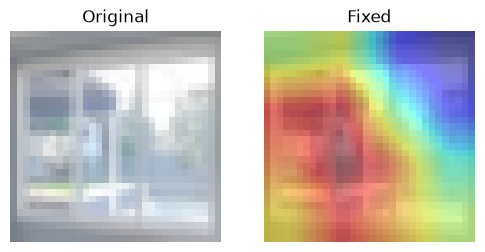

torch.Size([1, 128, 4, 4])


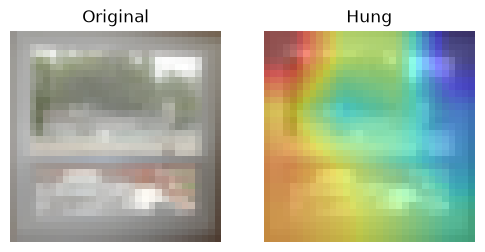

torch.Size([1, 128, 4, 4])


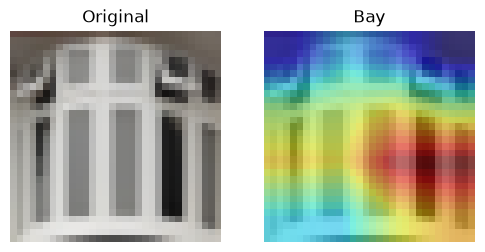

In [24]:
# ===== Task 6: Class Activation Maps =====
import matplotlib.pyplot as plt
import torch.nn.functional as F

def compute_cam(gap_model, image, predicted_class):
    """image: a single (1, 3, 32, 32) tensor. Returns a (4, 4) CAM (as a tensor)."""
    gap_model.eval()
    with torch.no_grad():
        image = image.unsqueeze(0)  # add batch dimension
        # BEGIN YOUR CODE HERE (~6-10 lines)
        # 1. Run `image` through conv1/pool, conv2/pool, conv3/pool
        #    (same three lines as in gap_model.forward) to get the last
        #    conv feature map `fmap`, shape (1, 128, 4, 4).
        x_conv1_relu_pool = gap_model.pool(torch.relu(gap_model.conv1(image)))
        x_conv2_relu_pool = gap_model.pool(torch.relu(gap_model.conv2(x_conv1_relu_pool)))
        fmap = gap_model.pool(torch.relu(gap_model.conv3(x_conv2_relu_pool)))
        print(fmap.shape)

        # 2. Get the weight vector for `predicted_class` from the GAP
        #    model's final linear layer: gap_model.fc.weight has shape
        #    (num_classes, 128); gap_model.fc.weight[predicted_class]
        #    has shape (128,).
        weight = gap_model.fc.weight[predicted_class]

        # 3. Compute the CAM as a weighted sum, over the 128 channels,
        #    of `fmap` using those weights -- i.e., for each of the 16
        #    (4x4) spatial positions: sum_k weight[k] * fmap[0, k, :, :].
        #    (Hint: torch.einsum('k,khw->hw', weight, fmap[0]) does this
        #    in one line; a broadcasted multiply + sum over dim 0 also
        #    works.)
        cam = torch.einsum("k,khw->hw", weight, fmap[0])

        # END YOUR CODE HERE
        return cam  # shape (4, 4)

def show_cam_overlay(image_tensor, cam, predicted_class, ax=None):
    """Upsamples `cam` to the image's resolution and overlays it as a heatmap.
    Uses `class_names` (loaded earlier from the dataset's folder names) to
    title the figure with a human-readable label instead of a raw index."""
    if ax is None:
        _, ax = plt.subplots(figsize=(1.5, 1.5))
    # BEGIN YOUR CODE HERE (~5-8 lines)
    # 1. Upsample `cam` (4x4) to (32, 32), e.g.:
    cam_up = F.interpolate(cam.view(1, 1, 4, 4), size=(32, 32),
                            mode='bilinear', align_corners=False)
    cam_up = cam_up.squeeze()

    # 2. Normalize cam_up to [0, 1] (e.g., (cam_up - cam_up.min()) /
    #    (cam_up.max() - cam_up.min() + 1e-8)) so it displays as a
    #    sensible heatmap regardless of the raw CAM value range.
    cam_up = (cam_up - cam_up.min()) / (cam_up.max() - cam_up.min() + 1e-8)

    # 3. Un-normalize `image_tensor` back to a displayable [0, 1] image
    #    (recall we normalized with mean=std=0.5, so displayed_img =
    #    image_tensor * 0.5 + 0.5)
    displayed_img = image_tensor * 0.5 + 0.5
    ax.imshow(displayed_img.permute(1, 2, 0).numpy())
    ax.imshow(cam_up.detach().numpy(), alpha=0.5, cmap='jet')
    
    # END YOUR CODE HERE
    ax.set_title(class_names[predicted_class])
    ax.axis('off')

# Pick 3+ correctly-classified test images (ideally from different
# predicted class), call compute_cam + show_cam_overlay(..., predicted_class)
# on each, and include the resulting figures in your submission.
selected = 0
selected_classes = set()
for inputs, labels in val_loader:
    # BEGIN YOUR CODE HERE 
    outputs = gap_model(inputs)
    _, predicted = torch.max(outputs, 1)
    # END YOUR CODE HERE 
    for i in range(len(labels)):
        # BEGIN YOUR CODE HERE (~6 lines)
        predicted_class = predicted[i].item()
        if selected < 3 and predicted_class not in selected_classes and predicted_class == labels[i]:
            image = inputs[i]
            cam = compute_cam(gap_model, image, predicted_class)

            fig, axes = plt.subplots(1, 2, figsize=(6, 3))

            displayed_img = image * 0.5 + 0.5

            axes[0].imshow(displayed_img.permute(1, 2, 0).numpy())
            axes[0].set_title("Original")
            axes[0].axis("off")

            show_cam_overlay(image, cam, predicted_class, ax=axes[1])

            plt.show()

            selected_classes.add(predicted_class)
            selected += 1
        # END YOUR CODE HERE 

In [25]:
# Save your trained GAP model's weights (e.g. to include in your
# submission, or to reload later without retraining).
torch.save(gap_model.state_dict(), 'gap_model.pth')
print('Saved gap_model weights to gap_model.pth')

Saved gap_model weights to gap_model.pth


## Task 7 (BONUS): Push past 60% accuracy

Using any combination of architecture changes, hyperparameter tuning, or changes to the training/optimization procedure, try to get your best model's test accuracy -- as computed by the TA from your submitted `predictions.csv` -- to at least 60%. A few directions to consider (you don't need all of them):

- **Architecture:** more conv layers or channels, `nn.BatchNorm2d`, `nn.Dropout`, or building on your `SimpleCNN_GAP` head from Task 5.
- **Hyperparameters:** learning rate, batch size, number of epochs, optimizer (e.g. `AdamW`, `SGD` with momentum), weight decay.
- **Training/optimization:** data augmentation in `train_transform` (e.g. `RandomHorizontalFlip`, `RandomRotation`, `ColorJitter`), a learning-rate scheduler, or a class-weighted loss (recall the class imbalance noted at the top of this problem).

In [ ]:
# ===== Task 7 (BONUS): push past 60% accuracy =====
# Build your improved model/optimizer below, train it, and evaluate it
# on val_loader. Reuse train()/evaluate() from Task 2, or write your own
# training loop if you're using a scheduler or other custom logic.

# BEGIN YOUR CODE HERE
bonus_model = 
bonus_optimizer = 
train(bonus_model, train_loader, criterion, bonus_optimizer, num_epochs= )
evaluate(bonus_model, val_loader)
# END YOUR CODE HERE

### Task 7 answer

_Briefly describe what you changed and why (2-4 sentences). Double-click this cell to edit._

## Submit predictions on the (unlabeled) test set

`windows_test_set.zip` ships without labels, so the cell below runs whichever of your trained models you consider best (swap in `model`, `gap_model`, or `bonus_model` as appropriate) over every image in `test_set/` and writes `predictions.csv`. Submit this file alongside your PDF -- the TA uses it to compute your real test accuracy, including whether you've met the bonus task's 60% threshold.

In [30]:
import glob
import os
import csv
from PIL import Image

class UnlabeledImageDataset(Dataset):
    """Loads every image file under `root` (searched recursively), with no
    label -- used for windows_test_set.zip, which ships unlabeled."""
    def __init__(self, root, transform):
        exts = ('*.png', '*.jpg', '*.jpeg', '*.bmp', '*.gif')
        self.paths = sorted(
            p for ext in exts
            for p in glob.glob(os.path.join(root, '**', ext), recursive=True)
        )
        self.transform = transform

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, idx):
        path = self.paths[idx]
        image = Image.open(path).convert('RGB')
        return self.transform(image), os.path.basename(path)

test_dataset = UnlabeledImageDataset('data/test_set', val_transform)
test_loader = DataLoader(test_dataset, batch_size=64, shuffle=False)

# Swap this for whichever of your trained models has the best validation
# accuracy (e.g. gap_model or bonus_model instead of model).
best_model = model
best_model.eval()

rows = []
with torch.no_grad():
    for images, filenames in test_loader:
        outputs = best_model(images)
        _, predicted = torch.max(outputs, 1)
        for fname, pred in zip(filenames, predicted.tolist()):
            rows.append((fname, class_names[pred]))

with open('predictions.csv', 'w', newline='') as f:
    writer = csv.writer(f)
    writer.writerow(['filename', 'predicted_label'])
    writer.writerows(rows)

print(f'Wrote {len(rows)} predictions to predictions.csv')

Wrote 496 predictions to predictions.csv


# Problem 2: Comparing Vanilla RNN with Variants in Sequence Modeling

# Problem 3: Fine-tune a DistilBERT model